# SMILE-D2: an introduction to the dataset

SMILE-D2 is a set of retrospective institutional liver ultrasound studies. Each
patient has two to four B-mode views of the liver, a pathology report from a liver
biopsy, and the METAVIR fibrosis stage that biopsy established.

It is the institutional dataset of *SMILE: A Structured Multi-Agent Clinical
Reasoning Framework for Liver Ultrasound Understanding*, where it was used to train
agents to write a report from the images.

This notebook is a tour: what is in the files, what the labels mean, what the images
look like, and the things about the dataset you should know before using it.

It needs only `numpy`, `matplotlib` and `pillow`.


## 1. What is in the bundle

One JSON holds every label and every path. The images sit beside it in two
variants, which Section 5 explains.


In [ ]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data = json.loads((ROOT / 'smile_d2_fibrosis.json').read_text(encoding='utf-8'))
records = data['records']

print(data['name'], 'v' + data['version'])
print(f"{data['n_patients']} patients, {data['n_images']} images")
print()
# for key in ('description'):
#     print(key + ':')
#     print(data[key])
#     print()


## 2. One patient

A record is a patient, not an image. The stage and the report describe the person;
every view of that person carries the same label.


In [6]:
example = records[0]
print('patient_id      ', example['patient_id'])
print('fibrosis_stage  ', example['fibrosis_stage'],
      '->', data['fibrosis_stage_scheme'][str(example['fibrosis_stage'])])
print('n_views         ', example['n_views'])
print()
print('report:')
for line in example['report'].splitlines():
    print('   ', line)
print()
for view in example['views']:
    print(f"  {view['view']}  frame {view['frame_size']}  sector {view['sector_bbox']}")


patient_id       D2-0001
fibrosis_stage   4 -> F4 - cirrhosis
n_views          4

report:
    Chronic hepatitis, undetermined cause, with
    - lobular activity, mild
    - portal-periportal activity, moderate
    - cirrhosis
    - steatosis, mild
    - lobular activity, mild

  view1  frame [1164, 873]  sector [0, 64, 1164, 809]
  view2  frame [1164, 873]  sector [185, 136, 827, 701]
  view3  frame [1164, 873]  sector [0, 64, 1164, 809]
  view4  frame [1164, 873]  sector [109, 111, 919, 694]


## 3. The labels

### METAVIR stage


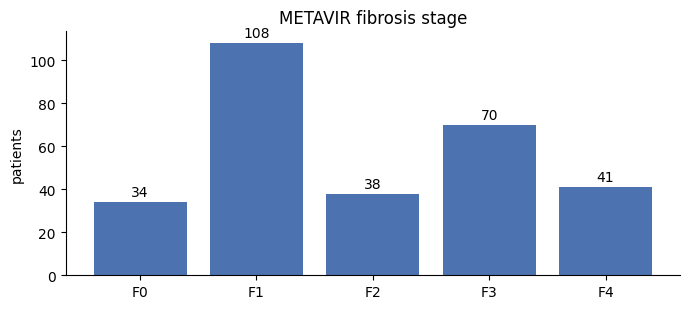

  F0   34 patients  (11.7%)  F0 - no fibrosis
  F1  108 patients  (37.1%)  F1 - portal fibrosis without septa
  F2   38 patients  (13.1%)  F2 - portal fibrosis with few septa
  F3   70 patients  (24.1%)  F3 - numerous septa without cirrhosis
  F4   41 patients  (14.1%)  F4 - cirrhosis


In [3]:
stages = Counter(r['fibrosis_stage'] for r in records)

fig, ax = plt.subplots(figsize=(7, 3.2))
keys = sorted(stages)
bars = ax.bar([f'F{k}' for k in keys], [stages[k] for k in keys], color='#4C72B0')
ax.bar_label(bars, padding=2)
ax.set_ylabel('patients')
ax.set_title('METAVIR fibrosis stage')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

for k in keys:
    print(f"  F{k}  {stages[k]:3d} patients  ({100 * stages[k] / len(records):4.1f}%)  "
          f"{data['fibrosis_stage_scheme'][str(k)]}")


### Pathology reports

The report is the reference text for report generation. It is the biopsy's own
wording, translated to English: a diagnosis line followed by graded findings.

In [4]:
lengths = [len(r['report']) for r in records]
print(f'report length: {min(lengths)}-{max(lengths)} characters, median {int(np.median(lengths))}')
print()
for r in records[:4]:
    print(f"--- {r['patient_id']}  (F{r['fibrosis_stage']})")
    for line in r['report'].splitlines():
        print('   ', line)
    print()


report length: 15-333 characters, median 146

--- D2-0001  (F4)
    Chronic hepatitis, undetermined cause, with
    - lobular activity, mild
    - portal-periportal activity, moderate
    - cirrhosis
    - steatosis, mild
    - lobular activity, mild

--- D2-0002  (F1)
    Chronic hepatitis, undetermined cause, with
    - lobular activity, mild
    - portal-periportal activity, mild
    - portal fibrosis

--- D2-0003  (F3)
    Chronic hepatitis, clinically autoimmune
    consistent with Primary biliary cholangitis, with
    - lobular activity, mild
    - portoperiportal activity, moderate
    - septal fibrosis
    - small granuloma

--- D2-0004  (F3)
    Chronic hepatitis, HBV, with
    - lobular activity, moderate
    - portal-periportal activity, moderate
    - septal fibrosis

